<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day23_Fairness_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()

Saving preregistration.json to preregistration.json
Saving final_config.json to final_config.json
Saving train.csv to train.csv


{'preregistration.json': b'{\n  "created": "2026-10-30T09:58:25",\n  "n_test_assumed": 72,\n  "regression": {\n    "early (no G1/G2)": {\n      "model": "Ridge",\n      "expected_rmse": 2.959,\n      "expected_range_95": [\n        2.482661817414654,\n        3.380634483890643\n      ]\n    },\n    "all features": {\n      "model": "Ridge",\n      "expected_rmse": 0.916,\n      "expected_range_95": [\n        0.7638558293208028,\n        1.0395304452064604\n      ]\n    }\n  },\n  "classification": {\n    "early (no G1/G2)": {\n      "model": "Logistic",\n      "expected_auc": 0.657,\n      "expected_range_95": [\n        0.5090681818181819,\n        0.8226607407788004\n      ],\n      "threshold": 0.12,\n      "train_oof_recall": 0.821917808219178,\n      "train_oof_precision": 0.2777777777777778,\n      "train_oof_flagged_share": 0.7578947368421053\n    },\n    "all features": {\n      "model": "Logistic",\n      "expected_auc": 0.943,\n      "expected_range_95": [\n        0.8996641

In [2]:
# Cell 1: setup, out-of-fold predictions and the practical-size thresholds fixed in advance
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import recall_score
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
cfg = json.load(open("final_config.json"))
pre = json.load(open("preregistration.json")) if os.path.exists("preregistration.json") else None

y = train["G3"]
y_risk = (y < 10).astype(int)
yv, rv = y.values, y_risk.values
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

def build_reg(name, params):
    base = {"Ridge": make_pipeline(StandardScaler(), Ridge()),
            "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
            "Gradient Boosting": GradientBoostingRegressor(random_state=42)}[name]
    return base.set_params(**params)

def build_clf(name, params):
    base = {"Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
            "Gradient Boosting": GradientBoostingClassifier(random_state=42)}[name]
    return base.set_params(**params)

kf = KFold(5, shuffle=True, random_state=42)
skf = StratifiedKFold(5, shuffle=True, random_state=42)

# practical-size thresholds, written down BEFORE looking at any group result
RESID_GAP, MAE_GAP, RATE_GAP = 0.5, 0.3, 0.10

oof_reg, oof_prob, thr = {}, {}, {}
for f, X in feature_sets.items():
    r, c = cfg["regression"][f], cfg["classification"][f]
    oof_reg[f] = cross_val_predict(build_reg(r["model"], r["params"]), X, y, cv=kf)
    oof_prob[f] = cross_val_predict(build_clf(c["model"], c["params"]), X, y_risk, cv=skf,
                                    method="predict_proba")[:, 1]
    if pre is not None:
        thr[f] = pre["classification"][f]["threshold"]
    else:
        ok = [t for t in np.linspace(0.01, 0.99, 99) if recall_score(rv, (oof_prob[f] >= t).astype(int)) >= 0.80]
        thr[f] = max(ok)
    print(f"{f:18s} regression: {r['model']:18s} | classifier: {c['model']:18s} | fixed threshold {thr[f]:.2f}")
print("\nStudents:", len(train), "| at risk:", rv.sum(), f"({rv.mean():.1%})")

early (no G1/G2)   regression: Ridge              | classifier: Logistic           | fixed threshold 0.12
all features       regression: Ridge              | classifier: Logistic           | fixed threshold 0.36

Students: 285 | at risk: 73 (25.6%)


In [3]:
# Cell 2: define the groups, then check how big each one is BEFORE comparing anything
A = X_all
groups = {
    "sex": ("female", (A["sex"] == 0).values, "male", (A["sex"] == 1).values),
    "school": ("GP", (A["school"] == 0).values, "MS", (A["school"] == 1).values),
    "address": ("rural", (A["address"] == 0).values, "urban", (A["address"] == 1).values),
    "family size": ("3 or fewer", (A["famsize"] == 0).values, "more than 3", (A["famsize"] == 1).values),
    "parents": ("living apart", (A["Pstatus"] == 0).values, "together", (A["Pstatus"] == 1).values),
    "internet at home": ("no", (A["internet"] == 0).values, "yes", (A["internet"] == 1).values),
    "wants higher ed.": ("no", (A["higher"] == 0).values, "yes", (A["higher"] == 1).values),
    "age": ("17 or younger", (A["age"] <= 17).values, "18 or older", (A["age"] >= 18).values),
    "mother's education": ("up to 9th grade", (A["Medu"] <= 2).values,
                           "secondary or higher", (A["Medu"] >= 3).values),
    "romantic relationship": ("no", (A["romantic"] == 0).values, "yes", (A["romantic"] == 1).values),
}

rows = []
for g, (la, ma, lb, mb) in groups.items():
    for lab, m in [(la, ma), (lb, mb)]:
        rows.append({"attribute": g, "group": lab, "n": int(m.sum()),
                     "at-risk n": int(rv[m].sum()), "actual at-risk %": round(100 * rv[m].mean(), 1),
                     "mean G3": round(yv[m].mean(), 2),
                     "small group?": "YES" if (m.sum() < 30 or rv[m].sum() < 15) else ""})
size_tbl = pd.DataFrame(rows)
print("Groups marked YES have fewer than 30 students or fewer than 15 at-risk students.")
print("Comparisons involving them cannot carry much weight.\n")
size_tbl

Groups marked YES have fewer than 30 students or fewer than 15 at-risk students.
Comparisons involving them cannot carry much weight.



,attribute,group,n,at-risk n,actual at-risk %,mean G3,small group?
0,sex,female,148,39,26.4,11.32,
1,sex,male,137,34,24.8,11.79,
2,school,GP,252,63,25.0,11.63,
3,school,MS,33,10,30.3,10.88,YES
4,address,rural,63,18,28.6,10.94,
5,address,urban,222,55,24.8,11.72,
6,family size,3 or fewer,85,22,25.9,11.68,
7,family size,more than 3,200,51,25.5,11.49,
8,parents,living apart,32,8,25.0,11.94,YES
9,parents,together,253,65,25.7,11.50,


In [4]:
# Cell 3: regression, are errors and tilt the same across groups? (95% bootstrap intervals for each gap)
rng = np.random.default_rng(0)
n = len(train)
boot_idx = [rng.integers(0, n, n) for _ in range(2000)]

def gap_with_ci(fn, ma, mb):
    """gap = metric(group B) - metric(group A), with a 95% bootstrap interval"""
    est = fn(np.where(mb)[0]) - fn(np.where(ma)[0])
    vals = []
    for i in boot_idx:
        a, b = i[ma[i]], i[mb[i]]
        if len(a) < 5 or len(b) < 5:
            continue
        v = fn(b) - fn(a)
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return est, lo, hi

rows = []
for f in feature_sets:
    resid = yv - oof_reg[f]                                   # actual minus predicted
    for g, (la, ma, lb, mb) in groups.items():
        e1, l1, h1 = gap_with_ci(lambda ix: resid[ix].mean(), ma, mb)
        e2, l2, h2 = gap_with_ci(lambda ix: np.abs(resid[ix]).mean(), ma, mb)
        d1 = (l1 > 0 or h1 < 0) and abs(e1) >= RESID_GAP
        d2 = (l2 > 0 or h2 < 0) and abs(e2) >= MAE_GAP
        rows.append({"features": f, "attribute": g, "B minus A": f"{lb} - {la}",
                     "n A / n B": f"{int(ma.sum())} / {int(mb.sum())}",
                     "mean resid A": round(resid[ma].mean(), 2), "mean resid B": round(resid[mb].mean(), 2),
                     "resid gap": round(e1, 2), "resid 95% CI": f"{l1:.2f} to {h1:.2f}",
                     "MAE gap": round(e2, 2), "MAE 95% CI": f"{l2:.2f} to {h2:.2f}",
                     "worth discussing": ("both" if d1 and d2 else "residual" if d1 else "MAE" if d2 else ""),
                     "CI excludes 0 (either)": ((l1 > 0 or h1 < 0) or (l2 > 0 or h2 < 0))})
reg_gaps = pd.DataFrame(rows)
print("Residual = actual - predicted. NEGATIVE means the group is OVER-predicted (the model is too optimistic).")
print(f"Practical size to discuss: residual gap >= {RESID_GAP}, MAE gap >= {MAE_GAP} grade points.\n")
reg_gaps.drop(columns="CI excludes 0 (either)")

Residual = actual - predicted. NEGATIVE means the group is OVER-predicted (the model is too optimistic).
Practical size to discuss: residual gap >= 0.5, MAE gap >= 0.3 grade points.



,features,attribute,B minus A,n A / n B,mean resid A,mean resid B,resid gap,resid 95% CI,MAE gap,MAE 95% CI,worth discussing
0,early (no G1/G2),sex,male - female,148 / 137,-0.13,0.06,0.19,-0.53 to 0.88,0.04,-0.35 to 0.45,
1,early (no G1/G2),school,MS - GP,252 / 33,-0.02,-0.20,-0.18,-1.20 to 0.79,-0.17,-0.74 to 0.40,
2,early (no G1/G2),address,urban - rural,63 / 222,-0.12,-0.02,0.10,-0.78 to 0.97,-0.00,-0.54 to 0.51,
3,early (no G1/G2),family size,more than 3 - 3 or fewer,85 / 200,-0.01,-0.05,-0.04,-0.81 to 0.66,0.05,-0.36 to 0.47,
4,early (no G1/G2),parents,together - living apart,32 / 253,0.12,-0.06,-0.18,-1.39 to 1.00,-0.30,-1.01 to 0.41,
5,early (no G1/G2),internet at home,yes - no,49 / 236,-0.38,0.03,0.41,-0.51 to 1.31,0.22,-0.37 to 0.80,
6,early (no G1/G2),wants higher ed.,yes - no,12 / 273,-0.13,-0.04,0.09,-1.06 to 1.27,0.79,0.16 to 1.38,MAE
7,early (no G1/G2),age,18 or older - 17 or younger,205 / 80,-0.06,-0.00,0.05,-0.74 to 0.84,0.07,-0.41 to 0.53,
8,early (no G1/G2),mother's education,secondary or higher - up to 9th grade,118 / 167,-0.12,0.01,0.14,-0.55 to 0.80,0.67,0.27 to 1.03,MAE
9,early (no G1/G2),romantic relationship,yes - no,197 / 88,-0.07,0.01,0.08,-0.64 to 0.77,-0.30,-0.67 to 0.09,


In [5]:
# Cell 4: at-risk flagging, does the flag work equally well for every group?
rows_g, rows_gap = [], []
for f in feature_sets:
    p = oof_prob[f]
    flag = (p >= thr[f]).astype(int)

    def flag_rate(ix, flag=flag):
        return flag[ix].mean()

    def recall_fn(ix, flag=flag):
        pos_ix = ix[rv[ix] == 1]
        return flag[pos_ix].mean() if len(pos_ix) else np.nan

    for g, (la, ma, lb, mb) in groups.items():
        for lab, m in [(la, ma), (lb, mb)]:
            pos = (rv == 1) & m
            fl = m & (flag == 1)
            rows_g.append({"features": f, "attribute": g, "group": lab, "n": int(m.sum()),
                           "at-risk n": int(pos.sum()),
                           "actual at-risk %": round(100 * rv[m].mean(), 1),
                           "mean predicted risk %": round(100 * p[m].mean(), 1),
                           "flagged %": round(100 * flag[m].mean(), 1),
                           "recall": round(flag[pos].mean(), 2) if pos.sum() else np.nan,
                           "precision": round(rv[fl].mean(), 2) if fl.sum() else np.nan})
        e1, l1, h1 = gap_with_ci(flag_rate, ma, mb)
        e2, l2, h2 = gap_with_ci(recall_fn, ma, mb)
        d1 = (l1 > 0 or h1 < 0) and abs(e1) >= RATE_GAP
        d2 = (l2 > 0 or h2 < 0) and abs(e2) >= RATE_GAP
        rows_gap.append({"features": f, "attribute": g, "B minus A": f"{lb} - {la}",
                         "flag-rate gap (pts)": round(100 * e1, 1), "flag-rate 95% CI": f"{100*l1:.0f} to {100*h1:.0f}",
                         "recall gap (pts)": round(100 * e2, 1), "recall 95% CI": f"{100*l2:.0f} to {100*h2:.0f}",
                         "worth discussing": ("both" if d1 and d2 else "flag rate" if d1 else "recall" if d2 else ""),
                         "CI excludes 0 (either)": ((l1 > 0 or h1 < 0) or (l2 > 0 or h2 < 0))})

clf_groups = pd.DataFrame(rows_g)
clf_gaps = pd.DataFrame(rows_gap)
print(f"Practical size to discuss: {int(RATE_GAP * 100)} percentage points.")
print("Compare 'flagged %' with 'actual at-risk %' INSIDE each group, and 'mean predicted risk %' with it too.\n")
clf_groups

Practical size to discuss: 10 percentage points.
Compare 'flagged %' with 'actual at-risk %' INSIDE each group, and 'mean predicted risk %' with it too.



,features,attribute,group,n,at-risk n,actual at-risk %,mean predicted risk %,flagged %,recall,precision
0,early (no G1/G2),sex,female,148,39,26.4,25.9,83.1,0.82,0.26
1,early (no G1/G2),sex,male,137,34,24.8,25.2,67.9,0.82,0.30
2,early (no G1/G2),school,GP,252,63,25.0,24.8,74.2,0.79,0.27
3,early (no G1/G2),school,MS,33,10,30.3,30.8,87.9,1.00,0.34
4,early (no G1/G2),address,rural,63,18,28.6,28.2,84.1,0.83,0.28
5,early (no G1/G2),address,urban,222,55,24.8,24.8,73.4,0.82,0.28
6,early (no G1/G2),family size,3 or fewer,85,22,25.9,27.3,87.1,0.95,0.28
7,early (no G1/G2),family size,more than 3,200,51,25.5,24.8,71.0,0.76,0.27
8,early (no G1/G2),parents,living apart,32,8,25.0,26.4,78.1,0.88,0.28
9,early (no G1/G2),parents,together,253,65,25.7,25.4,75.5,0.82,0.28


In [6]:
# Cell 5: the gaps for the classifier, and how many tests have we run?
clf_gaps.drop(columns="CI excludes 0 (either)")

,features,attribute,B minus A,flag-rate gap (pts),flag-rate 95% CI,recall gap (pts),recall 95% CI,worth discussing
0,early (no G1/G2),sex,male - female,-15.2,-25 to -5,0.3,-18 to 18,flag rate
1,early (no G1/G2),school,MS - GP,13.7,0 to 26,20.6,11 to 31,both
2,early (no G1/G2),address,urban - rural,-10.7,-21 to 0,-1.5,-21 to 21,
3,early (no G1/G2),family size,more than 3 - 3 or fewer,-16.1,-25 to -6,-19.0,-33 to -3,both
4,early (no G1/G2),parents,together - living apart,-2.6,-18 to 14,-6.0,-25 to 28,
5,early (no G1/G2),internet at home,yes - no,-12.0,-23 to 0,1.2,-20 to 25,
6,early (no G1/G2),wants higher ed.,yes - no,-25.3,-30 to -20,-19.7,-30 to -11,both
7,early (no G1/G2),age,18 or older - 17 or younger,21.5,13 to 30,22.4,8 to 37,both
8,early (no G1/G2),mother's education,secondary or higher - up to 9th grade,-5.2,-15 to 5,8.3,-10 to 27,
9,early (no G1/G2),romantic relationship,yes - no,3.8,-6 to 15,0.6,-20 to 19,


In [7]:
# Cell 6: the multiple-testing reality check
n_ci_tests = 2 * (len(reg_gaps) + len(clf_gaps))
n_excl = int(reg_gaps["CI excludes 0 (either)"].sum() * 1 + clf_gaps["CI excludes 0 (either)"].sum() * 1)
n_disc = int((reg_gaps["worth discussing"] != "").sum() + (clf_gaps["worth discussing"] != "").sum())

print(f"Interval tests run (two metrics per row): {n_ci_tests}")
print(f"By chance alone, about {0.05 * n_ci_tests:.0f} of them would show an interval that excludes zero at 95%")
print(f"Rows where at least one interval excludes zero: {n_excl}")
print(f"Rows that are ALSO practically large ('worth discussing'): {n_disc}\n")

flagged = pd.concat([
    reg_gaps[reg_gaps["worth discussing"] != ""][["features", "attribute", "B minus A", "n A / n B",
                                                  "resid gap", "resid 95% CI", "MAE gap", "worth discussing"]],
    clf_gaps[clf_gaps["worth discussing"] != ""][["features", "attribute", "B minus A",
                                                  "flag-rate gap (pts)", "recall gap (pts)", "worth discussing"]]],
    ignore_index=True)
print("Rows worth discussing (always check n and the interval before reading anything into them):")
flagged if len(flagged) else print("None. This is not evidence of fairness, it means no gap was both detectable and large.")

Interval tests run (two metrics per row): 80
By chance alone, about 4 of them would show an interval that excludes zero at 95%
Rows where at least one interval excludes zero: 10
Rows that are ALSO practically large ('worth discussing'): 10

Rows worth discussing (always check n and the interval before reading anything into them):


,features,attribute,B minus A,n A / n B,resid gap,resid 95% CI,MAE gap,worth discussing,flag-rate gap (pts),recall gap (pts)
0,early (no G1/G2),wants higher ed.,yes - no,12 / 273,0.09,-1.06 to 1.27,0.79,MAE,NaN,NaN
1,early (no G1/G2),mother's education,secondary or higher - up to 9th grade,118 / 167,0.14,-0.55 to 0.80,0.67,MAE,NaN,NaN
2,early (no G1/G2),sex,male - female,NaN,NaN,NaN,NaN,flag rate,-15.2,0.3
3,early (no G1/G2),school,MS - GP,NaN,NaN,NaN,NaN,both,13.7,20.6
4,early (no G1/G2),family size,more than 3 - 3 or fewer,NaN,NaN,NaN,NaN,both,-16.1,-19.0
5,early (no G1/G2),wants higher ed.,yes - no,NaN,NaN,NaN,NaN,both,-25.3,-19.7
6,early (no G1/G2),age,18 or older - 17 or younger,NaN,NaN,NaN,NaN,both,21.5,22.4
7,all features,school,MS - GP,NaN,NaN,NaN,NaN,recall,10.6,20.6
8,all features,wants higher ed.,yes - no,NaN,NaN,NaN,NaN,flag rate,-32.7,-3.9
9,all features,age,18 or older - 17 or younger,NaN,NaN,NaN,NaN,flag rate,14.6,10.6


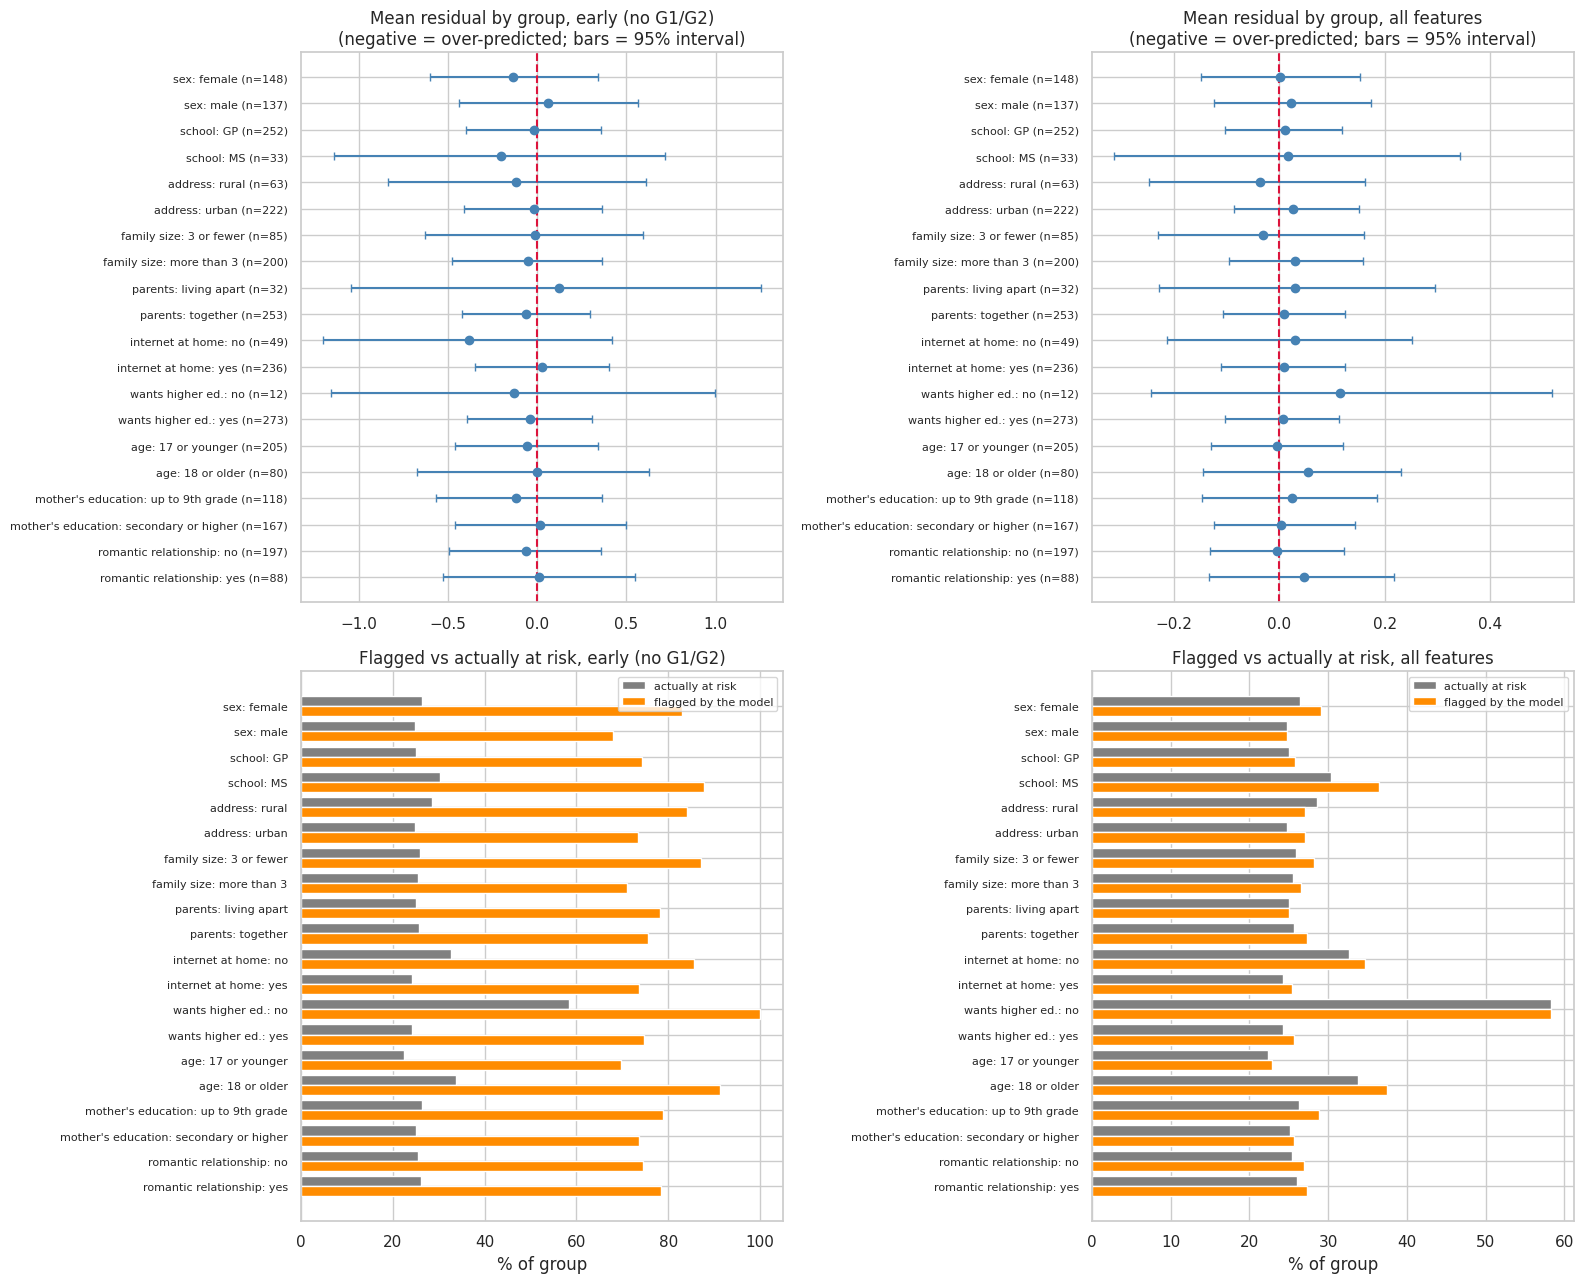

In [8]:
# Cell 7: one figure, the group-level picture
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for j, f in enumerate(feature_sets):
    resid = yv - oof_reg[f]
    names, means, los, his = [], [], [], []
    for g, (la, ma, lb, mb) in groups.items():
        for lab, m in [(la, ma), (lb, mb)]:
            ix = np.where(m)[0]
            bm = rng.choice(resid[ix], (2000, len(ix))).mean(axis=1)
            names.append(f"{g}: {lab} (n={len(ix)})")
            means.append(resid[ix].mean())
            los.append(np.percentile(bm, 2.5)); his.append(np.percentile(bm, 97.5))
    pos = np.arange(len(names))
    means, los, his = map(np.array, (means, los, his))
    axes[0, j].errorbar(means, pos, xerr=[means - los, his - means], fmt="o", color="steelblue", capsize=3)
    axes[0, j].axvline(0, color="crimson", linestyle="--")
    axes[0, j].set_yticks(pos); axes[0, j].set_yticklabels(names, fontsize=8); axes[0, j].invert_yaxis()
    axes[0, j].set_title(f"Mean residual by group, {f}\n(negative = over-predicted; bars = 95% interval)")

    sub = clf_groups[clf_groups.features == f].reset_index(drop=True)
    lab_ = (sub["attribute"] + ": " + sub["group"]).tolist()
    pos = np.arange(len(sub))
    axes[1, j].barh(pos - 0.2, sub["actual at-risk %"], 0.4, label="actually at risk", color="gray")
    axes[1, j].barh(pos + 0.2, sub["flagged %"], 0.4, label="flagged by the model", color="darkorange")
    axes[1, j].set_yticks(pos); axes[1, j].set_yticklabels(lab_, fontsize=8); axes[1, j].invert_yaxis()
    axes[1, j].set_xlabel("% of group"); axes[1, j].legend(fontsize=8)
    axes[1, j].set_title(f"Flagged vs actually at risk, {f}")
plt.tight_layout()
plt.savefig("fairness_audit.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Cell 8: fairness through unawareness, does deleting the sensitive column remove the gap?
rows = []
for attr in ["sex", "school", "address"]:
    _, ma, _, mb = groups[attr]
    for f, X in feature_sets.items():
        Xd = X.drop(columns=attr)
        r, c = cfg["regression"][f], cfg["classification"][f]
        res_with = yv - oof_reg[f]
        res_wo = yv - cross_val_predict(build_reg(r["model"], r["params"]), Xd, y, cv=kf)
        p_wo = cross_val_predict(build_clf(c["model"], c["params"]), Xd, y_risk, cv=skf, method="predict_proba")[:, 1]
        fl_w, fl_wo = (oof_prob[f] >= thr[f]).astype(int), (p_wo >= thr[f]).astype(int)
        rows.append({"attribute": attr, "features": f,
                     "residual gap, with column": round(res_with[mb].mean() - res_with[ma].mean(), 2),
                     "residual gap, without": round(res_wo[mb].mean() - res_wo[ma].mean(), 2),
                     "flag-rate gap pts, with": round(100 * (fl_w[mb].mean() - fl_w[ma].mean()), 1),
                     "flag-rate gap pts, without": round(100 * (fl_wo[mb].mean() - fl_wo[ma].mean()), 1)})
unaware = pd.DataFrame(rows)
print("Gaps are 'second group minus first group'. Differences between the columns are mostly noise:")
print("no intervals are shown, because the point is that deleting the column barely changes anything.\n")
display(unaware)

rows = []
cv_p = StratifiedKFold(5, shuffle=True, random_state=0)
for attr in ["sex", "school", "address"]:
    Xd = X_all.drop(columns=attr)
    auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                          Xd, X_all[attr], cv=cv_p, scoring="roc_auc")
    top = pd.Series(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
                    .fit(Xd, X_all[attr])[-1].coef_[0], index=Xd.columns)
    rows.append({"can the other columns predict...": attr, "cross-validated AUC": round(auc.mean(), 3),
                 "strongest proxies": ", ".join(top.abs().sort_values(ascending=False).head(4).index)})
proxy = pd.DataFrame(rows)
print("\nAUC 0.5 = the other columns contain no information about the attribute; 1.0 = they reveal it completely.")
proxy

Gaps are 'second group minus first group'. Differences between the columns are mostly noise:
no intervals are shown, because the point is that deleting the column barely changes anything.



,attribute,features,"residual gap, with column","residual gap, without","flag-rate gap pts, with","flag-rate gap pts, without"
0,sex,early (no G1/G2),0.19,0.44,-15.2,-13.9
1,sex,all features,0.02,-0.05,-4.2,-8.4
2,school,early (no G1/G2),-0.18,-0.46,13.7,6.4
3,school,all features,0.01,-0.11,10.6,10.6
4,address,early (no G1/G2),0.10,0.29,-10.7,-8.9
5,address,all features,0.06,0.09,0.0,1.4



AUC 0.5 = the other columns contain no information about the attribute; 1.0 = they reveal it completely.


,can the other columns predict...,cross-validated AUC,strongest proxies
0,sex,0.742,"G1, studytime, Mjob_teacher, G2"
1,school,0.864,"age, absences, Walc, Fjob_teacher"
2,address,0.595,"traveltime, activities, goout, age"


In [10]:
# Cell 9: the "no free lunch" demonstration, equalising recall changes everything else
def thr_for_recall(p, yy, target=0.80):
    ok = [t for t in np.linspace(0.01, 0.99, 99) if recall_score(yy, (p >= t).astype(int)) >= target]
    return max(ok) if ok else 0.01

rows = []
for attr in ["sex", "school"]:
    la, ma, lb, mb = groups[attr]
    for f in feature_sets:
        p = oof_prob[f]
        for lab, m in [(la, ma), (lb, mb)]:
            pos = (rv == 1) & m
            t_g = thr_for_recall(p[m], rv[m])
            for label, fl in [("common threshold", (p >= thr[f]).astype(int)),
                              ("per-group threshold", (p >= t_g).astype(int))]:
                sel = m & (fl == 1)
                rows.append({"attribute": attr, "features": f, "group": lab, "rule": label,
                             "threshold": round(thr[f] if label == "common threshold" else t_g, 2),
                             "recall": round(fl[pos].mean(), 2),
                             "flagged %": round(100 * fl[m].mean(), 1),
                             "precision": round(rv[sel].mean(), 2) if sel.sum() else np.nan})
tradeoff = pd.DataFrame(rows)
print("EXPLORATION ONLY. Nothing in the final model changes.")
print("Using different thresholds by sex or school means treating students differently by group,")
print("which raises ethical and legal questions that a school would need to settle first.\n")
tradeoff

EXPLORATION ONLY. Nothing in the final model changes.
Using different thresholds by sex or school means treating students differently by group,
which raises ethical and legal questions that a school would need to settle first.



,attribute,features,group,rule,threshold,recall,flagged %,precision
0,sex,early (no G1/G2),female,common threshold,0.12,0.82,83.1,0.26
1,sex,early (no G1/G2),female,per-group threshold,0.12,0.82,83.1,0.26
2,sex,early (no G1/G2),male,common threshold,0.12,0.82,67.9,0.30
3,sex,early (no G1/G2),male,per-group threshold,0.13,0.82,65.7,0.31
4,sex,all features,female,common threshold,0.36,0.79,29.1,0.72
5,sex,all features,female,per-group threshold,0.32,0.85,31.8,0.70
6,sex,all features,male,common threshold,0.36,0.85,24.8,0.85
7,sex,all features,male,per-group threshold,0.55,0.82,23.4,0.88
8,school,early (no G1/G2),GP,common threshold,0.12,0.79,74.2,0.27
9,school,early (no G1/G2),GP,per-group threshold,0.10,0.84,80.2,0.26


In [11]:
# Cell 10: save everything for the report
reg_gaps.to_csv("fairness_regression_gaps.csv", index=False)
clf_groups.to_csv("fairness_classification_groups.csv", index=False)
clf_gaps.to_csv("fairness_classification_gaps.csv", index=False)
tradeoff.to_csv("fairness_threshold_tradeoff.csv", index=False)
proxy.to_csv("fairness_proxy_check.csv", index=False)
size_tbl.to_csv("fairness_group_sizes.csv", index=False)
print("Saved 6 CSV files and fairness_audit.png")

Saved 6 CSV files and fairness_audit.png
